# Continuous Optimization in Data Science: Assignment 2

**Group 3**

**Group members:**
- Simon Carlén
- Alvin Stallgård

## Q1.1 Negative log-likelihood

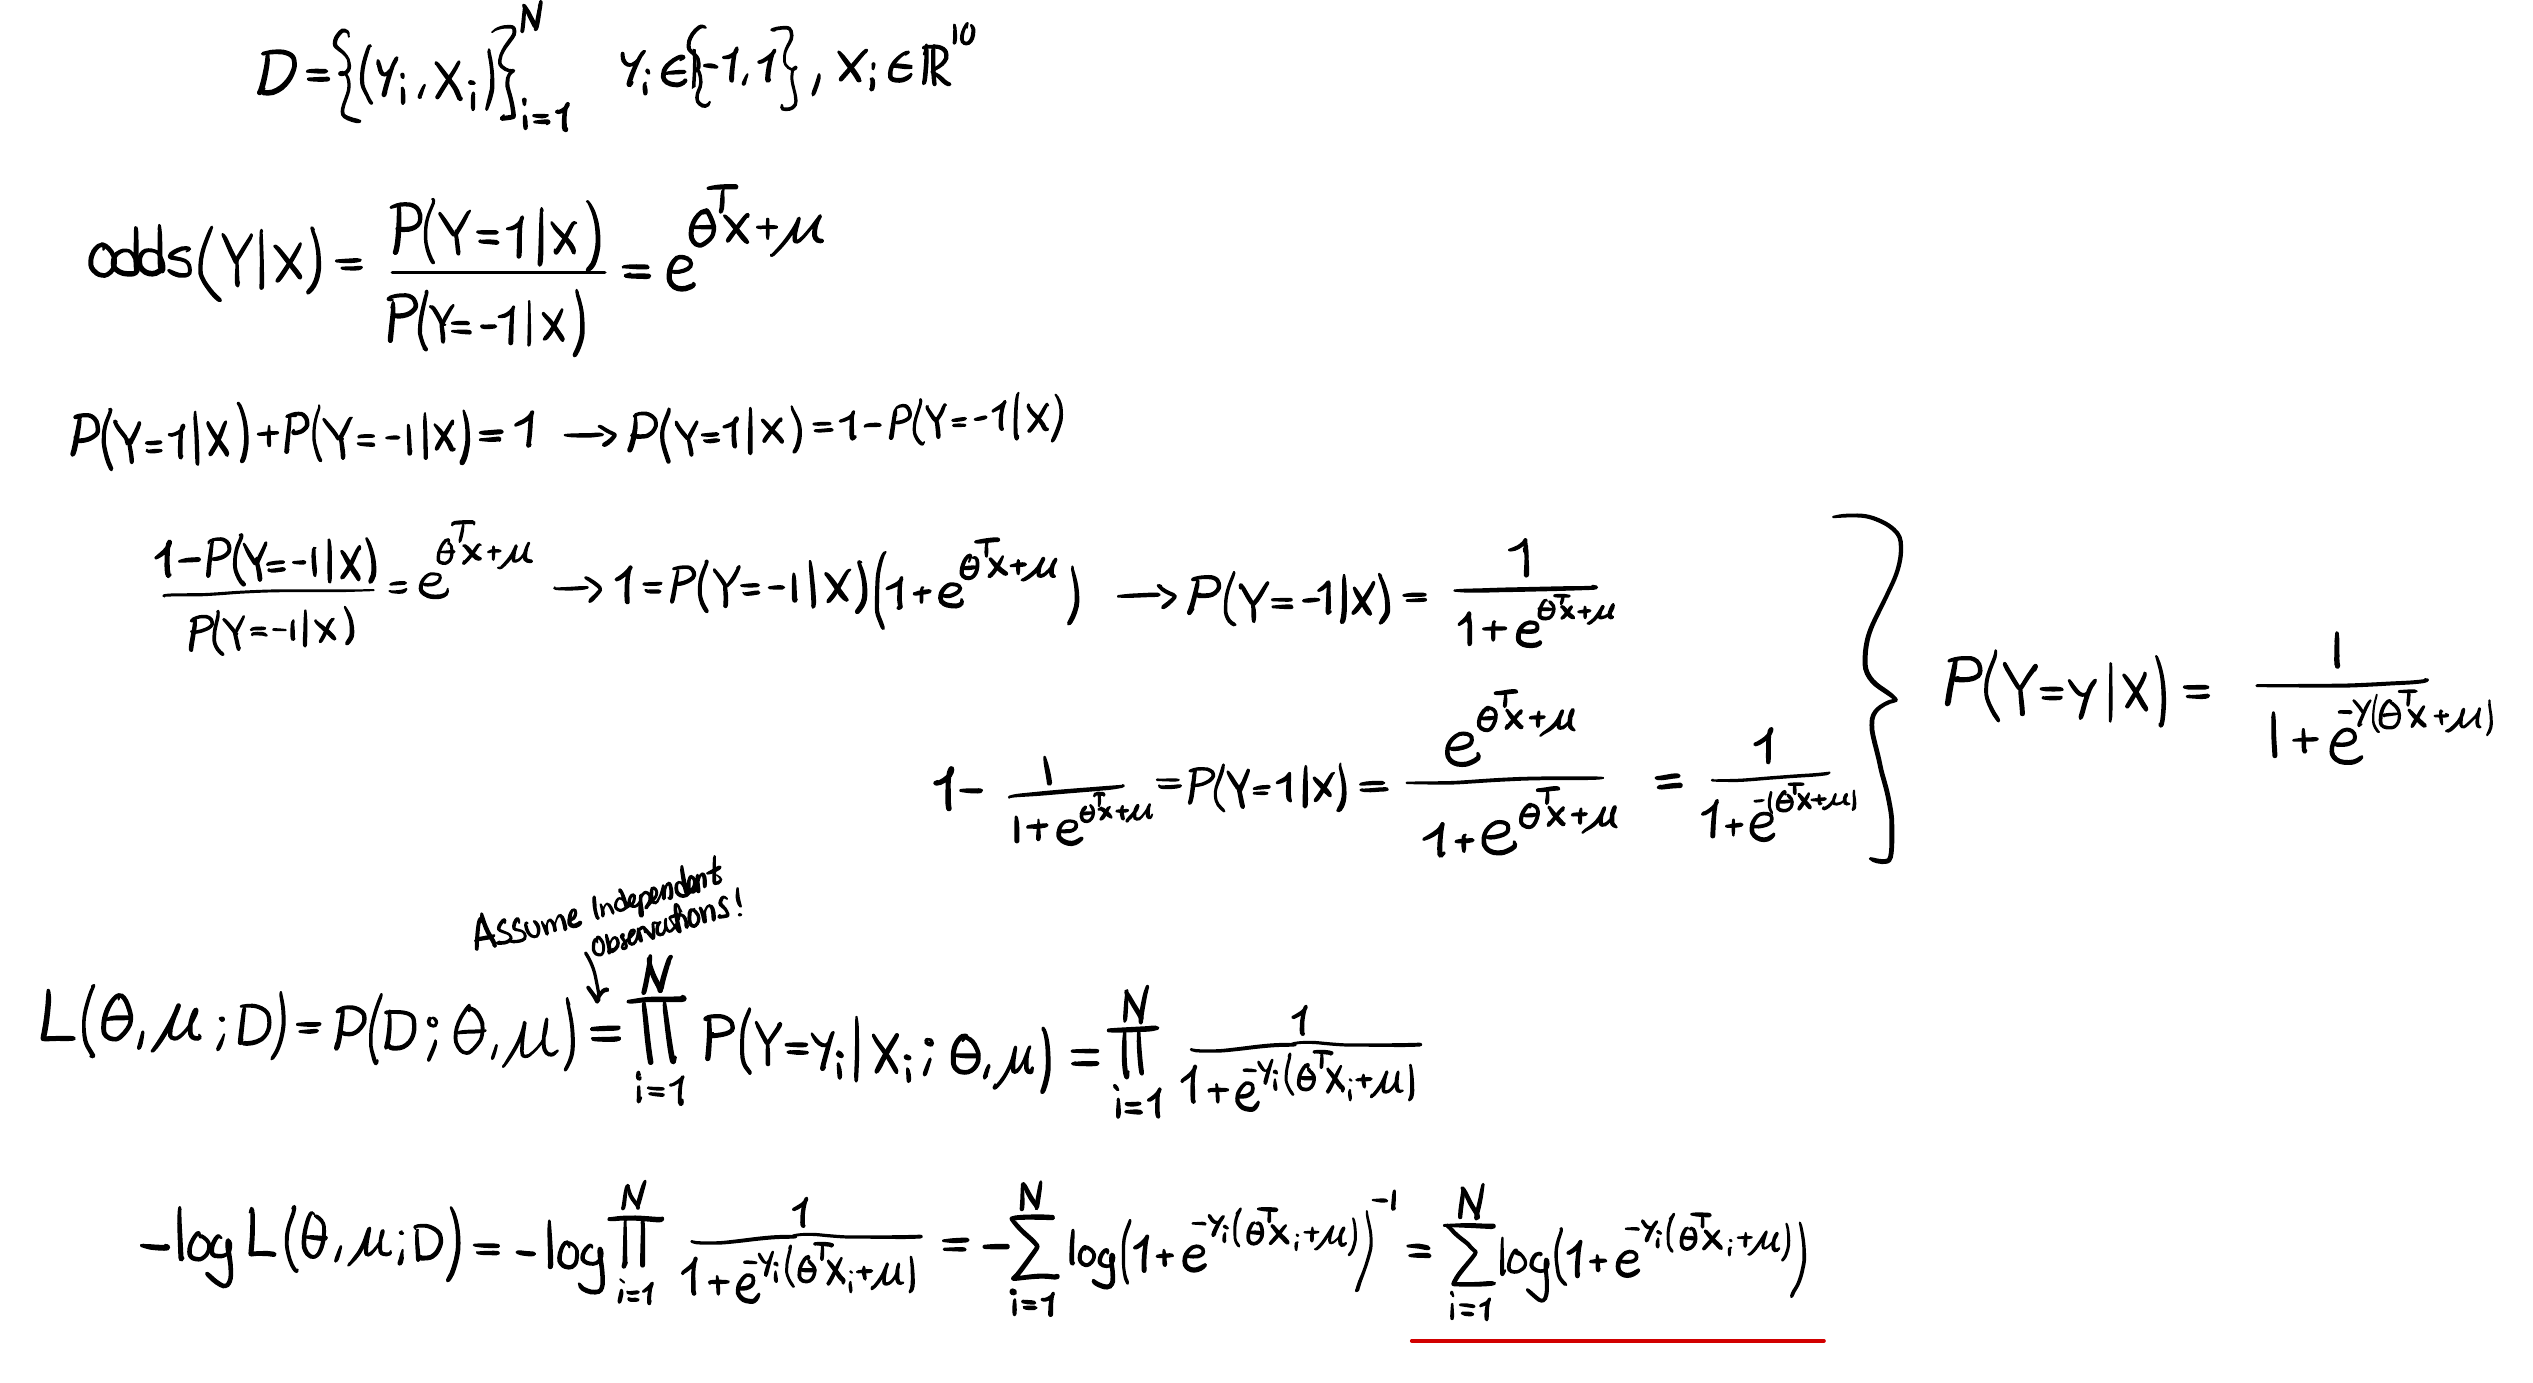

## Q1.2 Breast cancer data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [2]:
data = np.zeros((683, 10))
label = np.zeros(683)
with open('breast-cancer.txt') as f:
    for i, line in enumerate(f):
        parts = line.split()
        label[i] = (float(parts[0]) - 2) / 2
        data[i] = [float(p.split(':')[1]) for p in parts[1:11]]

data_scaled = data.copy()
data_scaled[:, 0] /= 1e6

n_train = 500
print(data.shape)

(683, 10)


In [3]:
for name, X in [('as is', data), ('divided by 1e6', data_scaled)]:
    X_train, X_test = X[:n_train], X[n_train:]
    y_train, y_test = label[:n_train], label[n_train:]

    clf = LogisticRegression(random_state=0).fit(X_train, y_train)

    theta, mu = clf.coef_, clf.intercept_

    odds = np.exp(X_test @ theta.ravel() + mu)
    accuracy = np.mean((odds > 1) == y_test)

    print(f'{name}: theta={theta.ravel().round(3)}, mu={mu[0]:.3f}, accuracy={accuracy:.3f}')

as is: theta=[-0.     0.412  0.276  0.313  0.121 -0.199  0.479 -0.103  0.161  0.215], mu=-0.348, accuracy=0.962
divided by 1e6: theta=[ 0.099  0.521 -0.055  0.317  0.293  0.124  0.363  0.354  0.194  0.439], mu=-9.251, accuracy=1.000


/Users/simonc/Coding/VSCode/coding-playground/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Report

**(a) Does dividing variable 1 by $10^6$ give a different solution? Why?**

Yes, all the coefficients and the intercept change. Without regularization, scaling a variable would only rescale its own coefficient and the predictions would stay the same. But sklearn uses L2 regularization by default, so the penalty depends on the scale of the variables and the optimal solution moves. In the first case the solver also did not converge, because the very large values in variable 1 make the problem badly scaled.

**(b) What can we learn from $\theta$? Does any gene have a bigger effect on cancer?**

A positive coefficient means that a higher value of the variable increases the odds of cancer, and a bigger coefficient means a stronger effect. Variables 2 to 10 are on the same scale, so we can compare them directly, and in the scaled model variables 2 and 10 seem to matter most. The variables are probably correlated, so the coefficients show association rather than cause. Variable 1 looks like a sample ID, so its coefficient should not be interpreted.

**(c) How good is the accuracy? Why, and what are the practical considerations for using the model?**

The accuracy is very high, which suggests that the classes are easy to separate. However, the test set is small and most samples have no cancer, so even a model that always predicts no cancer would get a fairly high accuracy. In practice a missed cancer case is worse than a false alarm, so the false negatives should be checked separately. The model should also be tested on more data, and new data must be preprocessed in the same way, before it is used to support a doctor's decision.

## Q1.3 Linear classification

**(a)**

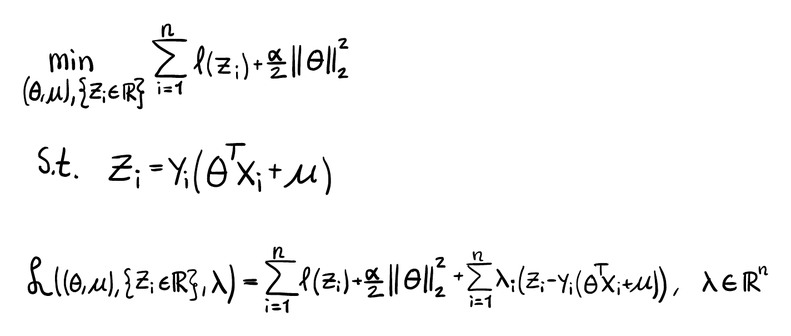

**Slater's condition**

- *Convex objective.* Since $\ell$ is convex, $\sum_{i=1}^n\ell(z_i)$ is convex. Since $\lVert\theta\rVert_2^2$ is convex and $\alpha\ge0$, $\frac{\alpha}{2}\lVert\theta\rVert_2^2$ is convex. A sum of convex functions is convex, so the objective is convex.
- *Affine constraints.* The constraints are linear in $(\theta,\mu,z)$ and there are no inequality constraints, so the constraints are affine.
- *Feasible point.* $\ell$ is finite on all of $\mathbb{R}$, so the objective is defined for every $(\theta,\mu,z)\in\mathbb{R}^m\times\mathbb{R}\times\mathbb{R}^n$. It is therefore enough to find one point that satisfies the constraints, e.g. $\theta=0,\ \mu=0,\ z=0$. Then $z_i=Y_i(\theta^T\mathbf{x}_i+\mu)$ holds for all $i$, so the point is feasible.

The problem is convex, the constraints are affine and a feasible point exists, so Slater's condition is satisfied.

**(b)**

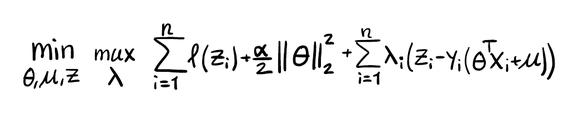

Since Slater's condition holds, strong duality holds and we can interchange min and max. The Lagrangian then separates into one part each for $z_i$, $\theta$ and $\mu$:

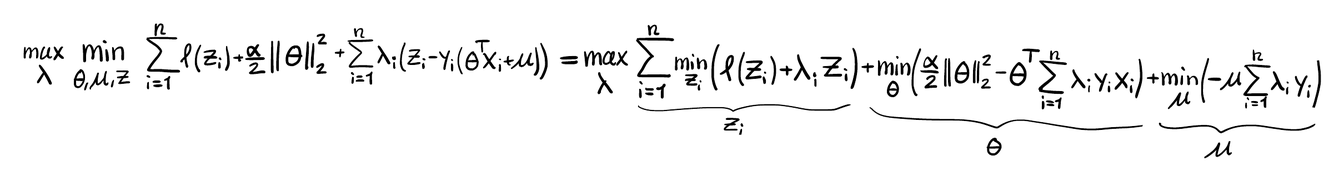

**$z_i$:** Using the definition of the convex conjugate, $\ell^{\ast}(s)=\sup_z\big(sz-\ell(z)\big)$,

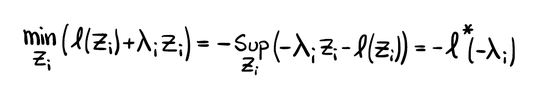

**$\theta$:** The function is convex and differentiable in $\theta$, so we set the gradient to zero:

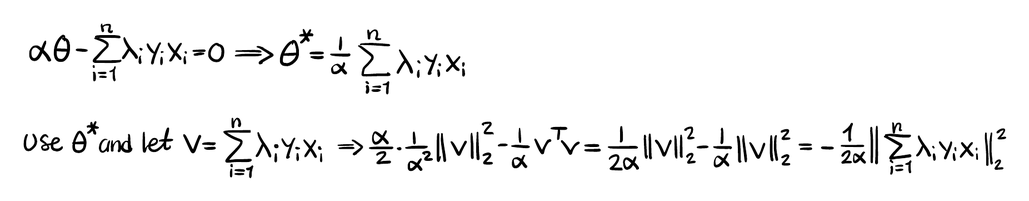

**$\mu$:** The term is linear in $\mu$, so

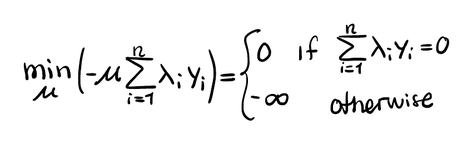

and the outer max never chooses $-\infty$, so we get the constraint $\sum_{i=1}^n\lambda_iY_i=0$.

Combining these three results, the dual problem is

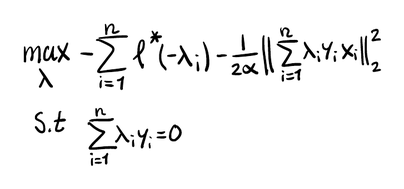

and maximizing $-f$ is equivalent to minimizing $f$:

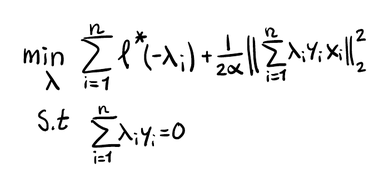

Substitute $\lambda_i\to-\lambda_i$. The norm is unchanged since $\lVert-v\rVert_2=\lVert v\rVert_2$, and the constraint is unchanged since $-\sum_i\lambda_iY_i=0\Leftrightarrow\sum_i\lambda_iY_i=0$. This gives

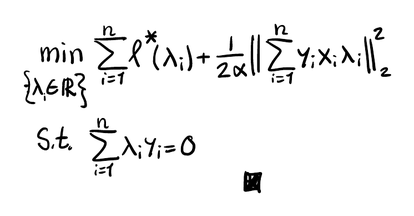

**(c)**

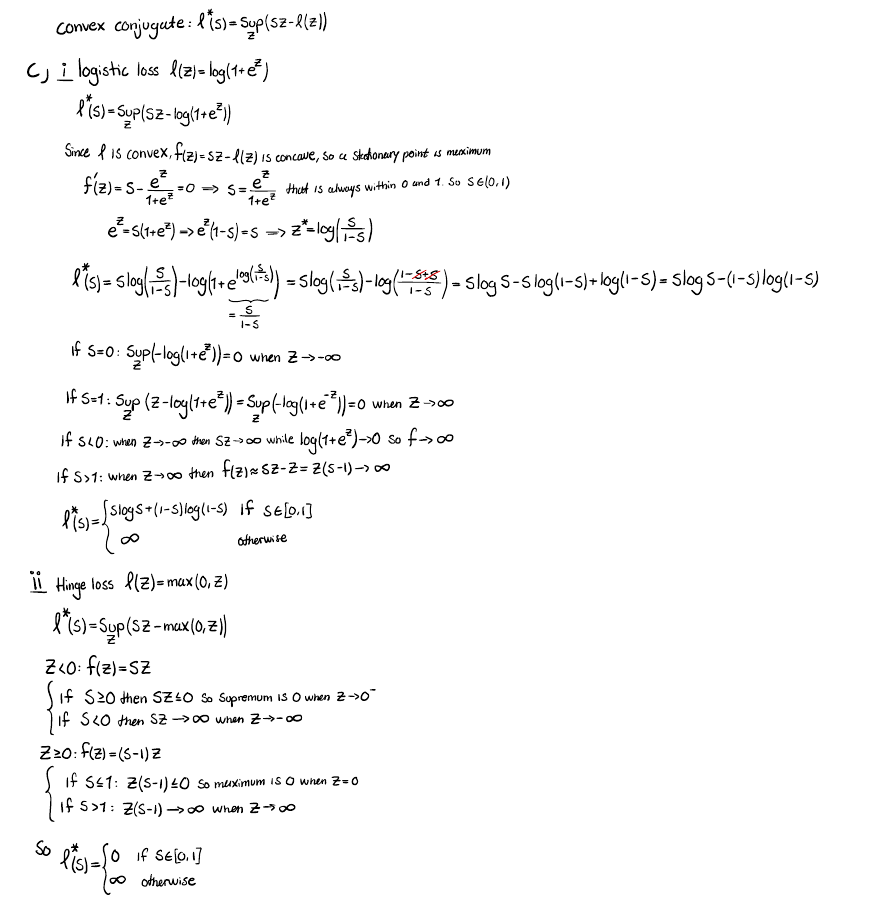

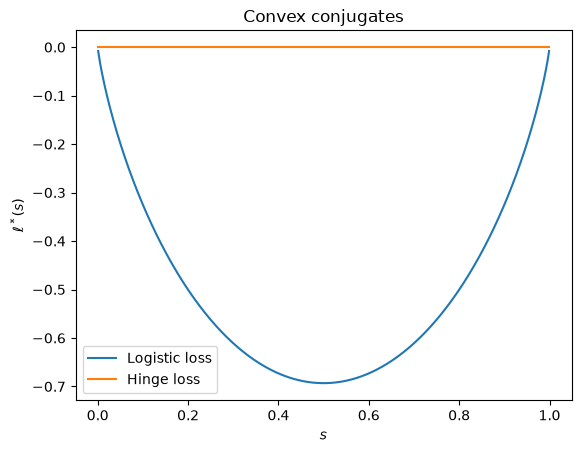

In [4]:
s = np.linspace(0.001, 0.999, 500)
logistic_conj = s * np.log(s) + (1 - s) * np.log(1 - s)
hinge_conj = np.zeros_like(s)

plt.plot(s, logistic_conj, label='Logistic loss')
plt.plot(s, hinge_conj, label='Hinge loss')
plt.xlabel('$s$')
plt.ylabel('$\\ell^*(s)$')
plt.title('Convex conjugates')
plt.legend()
plt.show()

## Q1.4 Risk of SVM and logistic regression

In [5]:
from sklearn import svm

def error_calc(alpha, n, d, beta):
    theta0 = np.ones(d)
    X = np.random.randn(n, d)
    p = 1 / (1 + np.exp(-beta * X @ theta0))
    Y = np.where(np.random.rand(n) < p, 1, -1)
    lr = LogisticRegression(C=1/alpha).fit(X, Y)
    sv = svm.SVC(C=1/alpha, kernel='linear').fit(X, Y)
    error_LR = np.sum((lr.coef_.ravel() - theta0)**2)
    error_SVM = np.sum((sv.coef_.ravel() - theta0)**2)
    return error_LR, error_SVM

def avg_risk_calc(alpha, n, d, beta, runs=1000):
    errors = np.array([error_calc(alpha, n, d, beta) for _ in range(runs)])
    MSE_LR, MSE_SVM = errors.mean(axis=0)
    return MSE_LR, MSE_SVM

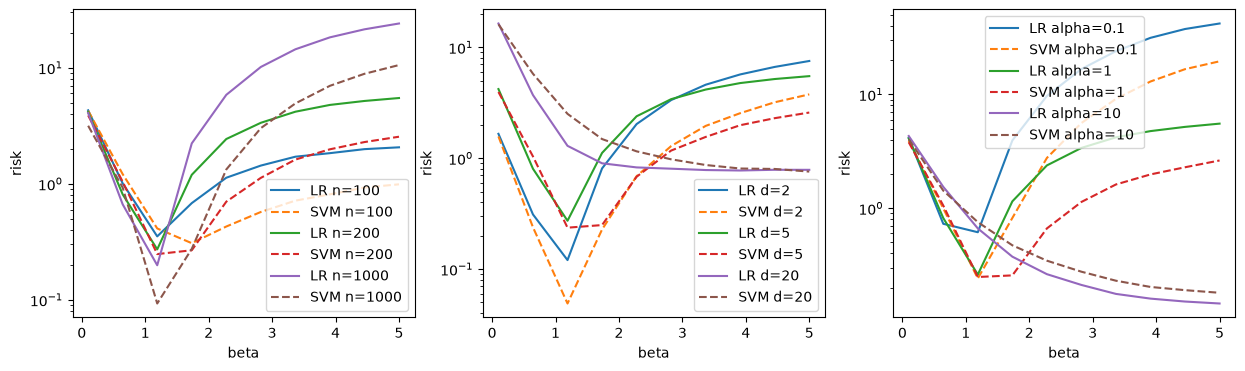

In [6]:
betas = np.linspace(0.1, 5, 10)
np.random.seed(0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for n in [100, 200, 1000]:
    risks = np.array([avg_risk_calc(1, n, 5, b) for b in betas])
    axes[0].plot(betas, risks[:, 0], label=f'LR n={n}')
    axes[0].plot(betas, risks[:, 1], '--', label=f'SVM n={n}')

for d in [2, 5, 20]:
    risks = np.array([avg_risk_calc(1, 200, d, b) for b in betas])
    axes[1].plot(betas, risks[:, 0], label=f'LR d={d}')
    axes[1].plot(betas, risks[:, 1], '--', label=f'SVM d={d}')

for alpha in [0.1, 1, 10]:
    risks = np.array([avg_risk_calc(alpha, 200, 5, b) for b in betas])
    axes[2].plot(betas, risks[:, 0], label=f'LR alpha={alpha}')
    axes[2].plot(betas, risks[:, 1], '--', label=f'SVM alpha={alpha}')

for ax in axes:
    ax.set_xlabel('beta')
    ax.set_ylabel('risk')
    ax.set_yscale('log')
    ax.legend()
plt.show()

#### Report

**(a) Risk as a function of $\beta$.**

The plots show the risk for $\beta\in[0.1,5]$ with $n\in\{100,200,1000\}$, $d\in\{2,5,20\}$ and $\alpha\in\{0.1,1,10\}$, where one parameter is changed at a time around $n=200,\ d=5,\ \alpha=1$. For most settings the risk is high for small $\beta$, has a minimum around $\beta\approx1$ and then grows again. The reason is that the labels follow the logistic model with parameter $\beta\boldsymbol{\theta}_0$, so logistic regression estimates roughly $\beta\boldsymbol{\theta}_0$ (shrunk a bit by the regularization), while the error is measured against $\boldsymbol{\theta}_0$. The estimate is therefore closest to $\boldsymbol{\theta}_0$ when $\beta$ is close to 1. For small $\beta$ the labels are almost random, so the coefficients are close to 0 and the error is close to $\lVert\boldsymbol{\theta}_0\rVert_2^2=d$.

**(b) Effect of $n$, $d$ and $\alpha$ on the risk curves.**

- *n:* A larger $n$ gives a lower minimum since there is more data and less variance. But the loss term grows with $n$ while the penalty stays the same, so the regularization matters less and the coefficients get closer to $\beta\boldsymbol{\theta}_0$. This makes the risk grow faster for large $\beta$.
- *d:* With more features there are more parameters to estimate from the same data, so the minimum gets higher. Also $t_i=\boldsymbol{\theta}_0^T\mathbf{x}_i$ has variance $d$, so for $d=20$ the data is almost separable already for small $\beta$, the regularization keeps the coefficients small and the curve just decreases with $\beta$.
- *α:* A larger $\alpha$ shrinks the coefficients more. For $\alpha=10$ this cancels the growth for large $\beta$ and the risk keeps decreasing, while for $\alpha=0.1$ the coefficients follow $\beta\boldsymbol{\theta}_0$ and the risk becomes large.

**(c) Which method gives the lower risk curve, and why?**

For small $\beta$ the two methods are about the same, but for $\beta$ above 1 the SVM gives a clearly lower risk in almost all settings (for $d=20$ they are about the same and for $\alpha=10$ logistic regression is slightly lower). The hinge loss is zero once a point is on the right side with enough margin, so the SVM does not get any reward for making the coefficients larger, and their size is mainly set by the margin and the regularization. The logistic loss is never zero, so logistic regression keeps scaling the coefficients towards $\beta\boldsymbol{\theta}_0$. Logistic regression is the correct model for this data, so it would be the better choice if we compared to $\beta\boldsymbol{\theta}_0$, but since the risk is measured against $\boldsymbol{\theta}_0$ the SVM ends up closer for large $\beta$.

## Q2.1 Bregman divergence of the squared norm

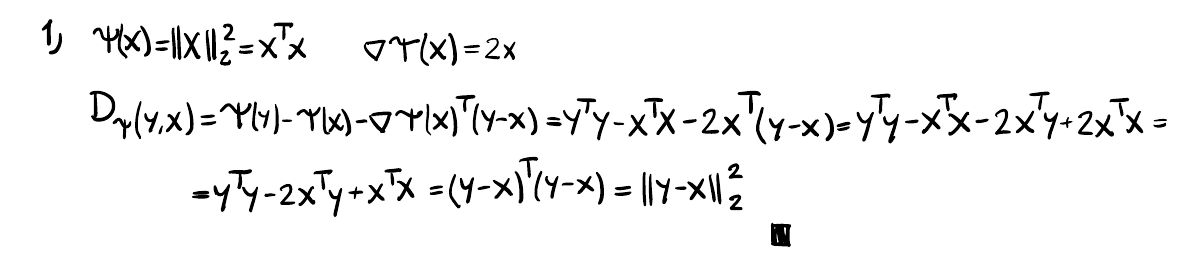

## Q2.2 Bregman divergence of the negative entropy

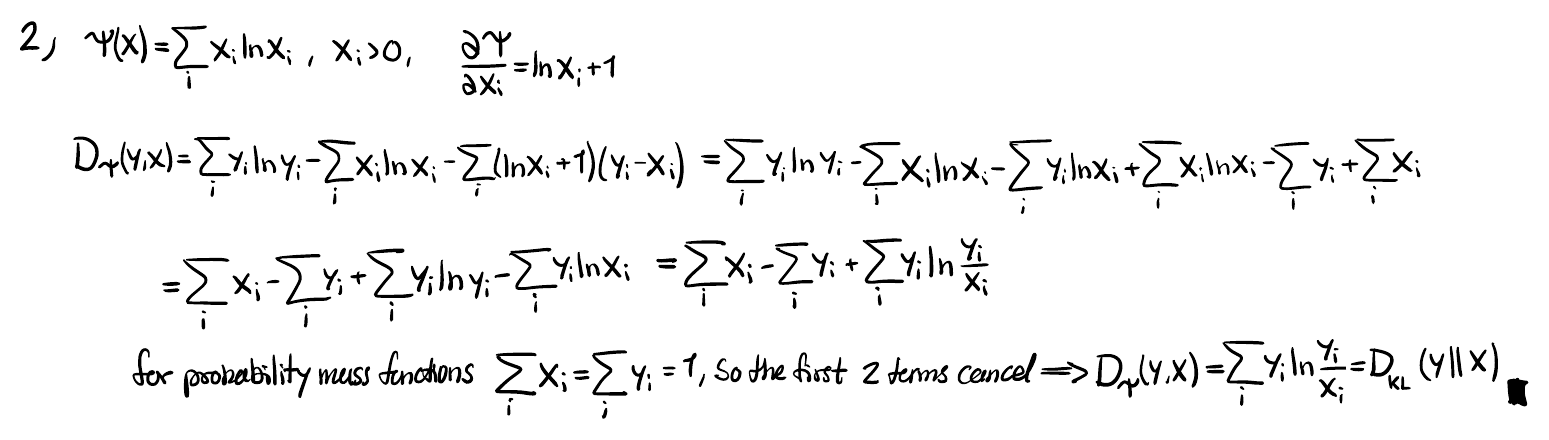